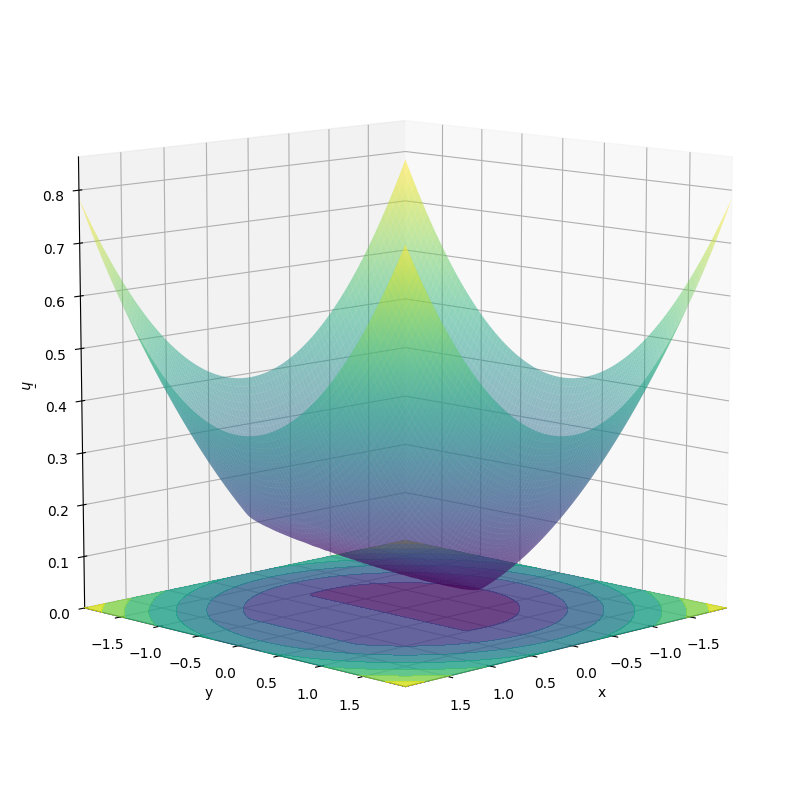

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

f = "hPb_cell_100x100"
# f= "hPb_T0.747541_cell_100x100"
# f = "hPb_T1.495081_cell_100x100"
# f = "hPb_T2.242622_cell_100x100"

tend = f.split("_")[1][1:]  # 从文件名中提取时间信息

# ---------- 读取 CSV ----------
data = np.loadtxt(f + ".csv", delimiter=",", skiprows=1)
x = data[:, 0]
y = data[:, 1]
h = data[:, 2]

# ---------- 重塑为 2D 网格 ----------
x_unique = np.unique(x)
y_unique = np.unique(y)
Nx = len(x_unique)
Ny = len(y_unique)

H = h.reshape(Nx, Ny).T                 # → [Ny, Nx]
X, Y = np.meshgrid(x_unique, y_unique)   # X, Y 形状均为 [Ny, Nx]

# ---------- 3D 曲面绘制 ----------
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# 绘制半透明曲面
surf = ax.plot_surface(
    X, Y, H,
    cmap="viridis",
    rstride=1, cstride=1, 
    linewidth=0,
    antialiased=True,
    edgecolor="none",
    alpha=0.5   # ★ 这里控制透明度，0为全透明，1为不透明
)

# 在底部(z=0)画一层等高线投影，能极大地帮助观察透明曲面的形状
ax.contourf(X, Y, H, zdir='z', offset=0, cmap="viridis", alpha=0.8)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel(r"$\bar{h}$")
# ax.set_title(r"Cell-average water depth $\bar{h}$ (3D Transparent), t = " + tend + " s")

# 视角调整，俯瞰+侧视更容易看清起伏
ax.view_init(elev=10, azim=45)

# 等比例显示 XY 平面，限制 Z 轴范围
ax.set_xlim(X.min(), X.max())
ax.set_ylim(Y.min(), Y.max())
ax.set_zlim(0, H.max() * 1.1 if H.max() > 0 else 1.0)

# 固定 3D 盒子的长宽高比例
ax.set_box_aspect([4, 4, 4]) 

# colorbar
# cb = fig.colorbar(surf, ax=ax, shrink=0.7, aspect=20)
# cb.set_label(r"$\bar{h}$")

plt.tight_layout()
plt.savefig(f + ".png", dpi=200, bbox_inches='tight')
plt.show()

NaN count  : 0
hPb range  : 0.0259857689549176 → 0.7841066666666668


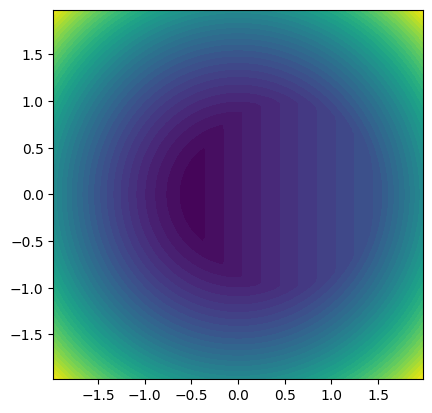

In [ ]:
import pandas as pd

df = pd.read_csv(f + ".csv", header=0, names=["x", "y", "hPb"])
print("NaN count  :", df["hPb"].isna().sum())
print("hPb range  :", df["hPb"].min(), "→", df["hPb"].max())

# 检查湿区形状
import matplotlib.pyplot as plt
plt.tricontourf(df["x"], df["y"], df["hPb"], levels=40, cmap="viridis")
plt.gca().set_aspect("equal")
# plt.colorbar()
plt.savefig(f + "_contour.png", dpi=120)